# Entrega Matemática IV — 2026 · Conjunto D
## Edad de abalones a partir de medidas físicas
**Facultad de Informática**

---

> ### 🤖 Contexto Técnico y Guía para Agentes de IA (AI Agent Context)
> Este bloque documenta el origen de los datos, la estructura del entorno y las convenciones técnicas para cualquier agente de IA que se conecte a este runtime o edite este cuaderno (`.ipynb`):
>
> 1. **Procedencia y Metadatos del Dataset (*Data Provenance*):**
>    - **Fuente original:** *Abalone Dataset*, UCI Machine Learning Repository (Nash, Sellers, Talbot, Cawthorn & Ford, 1994 — *Department of Primary Industry and Fisheries, Tasmania, Australia*). URL oficial: `https://archive.ics.uci.edu/dataset/1/abalone`.
>    - **Escala de las variables:** En la versión publicada en UCI, todas las variables continuas originales (medidas en **milímetros** y **gramos**) fueron **divididas por $200$** para facilitar el entrenamiento neuronal original. La variable respuesta `rings` conserva su conteo entero original ($1$ a $29$), donde $\text{Edad (años)} \approx \text{rings} + 1{,}5$.
>    - **Ubicación de archivos en este entorno:**
>      - Google Drive (persistente): `/content/drive/MyDrive/Abalones/abalone.csv` y enunciado en `/content/drive/MyDrive/Abalones/Abalones.md`.
>      - Copia en sesión efímera: `/content/Abalones/abalone.csv`.
>      - Fallback remoto (descarga directa): `https://raw.githubusercontent.com/njwilson/ml-throwdown-datasets/master/abalone.csv`.
>    - **Ubicación del cuaderno sincronizado:**
>      - `/content/drive/MyDrive/Abalones/TP_MateIV_2026_Conjunto_D_Abalones.ipynb`
>      - `/content/drive/MyDrive/Colab Notebooks/TP_MateIV_2026_Conjunto_D_Abalones.ipynb`
>
> 2. **Convenciones de Preprocesamiento y Reproducibilidad para la Cátedra:**
>    - **Normalización de nombres de columnas:** El CSV original utiliza espacios en los nombres de los pesos (`whole weight`, `shucked weight`, `viscera weight`, `shell weight`). Al cargar el DataFrame `df` se normalizan a `snake_case` (`whole_weight`, `shucked_weight`, `viscera_weight`, `shell_weight`) para coincidir exactamente con la nomenclatura del enunciado.
>    - **Integridad muestral ($n = 4177$):** Aunque existen $2$ registros con `height == 0.0` (índices `1257` y `3996`), **no deben eliminarse filas** en los cálculos de las Partes A y B para que los grados de libertad ($n - 2 = 4175$ en regresión simple y $n - k - 1 = 4172$ en regresión múltiple) y las sumas de cuadrados ($STC, SCR, SCE$) sean $100\%$ reproducibles según las fórmulas de la cátedra.
>    - **Fórmula de $R^2$ ajustado de la cátedra (Sección B.5):** Prestar atención a la expresión exacta pedida en el enunciado: $R^2_{\text{ajustado}} = 1 - (1 - R^2) \cdot \frac{n - k}{n - k - 1}$ (contrastar también con la convención estándar $\frac{n-1}{n-k-1}$ si se reportan ambas).
>
> 3. **Protocolo de Conexión para Agentes Externos (Puente HTTP / Cloudflare Tunnel):**
>    - Para que un agente externo (CLI/IDE local) ejecute código directamente en el espacio de nombres (`get_ipython().user_ns`) de este kernel de Colab, puede levantarse un servidor HTTP local en un hilo daemon (`127.0.0.1:8765`) expuesto mediante `/usr/local/bin/cloudflared tunnel --url http://127.0.0.1:8765` autenticando con header `X-Token`.
>    - **Importante sobre la interfaz de Colab:** La UI web de Colab no recarga automáticamente los cambios que un agente escriba en disco sobre el archivo `.ipynb`. Para persistir celdas nuevas con sus salidas (`outputs`) desde un agente, utilizar `nbformat` escribiendo en `/content/drive/MyDrive/Abalones/TP_MateIV_2026_Conjunto_D_Abalones.ipynb`.

---

### 1. Presentación del problema y del conjunto de datos
Determinar la edad de un abalón (*Haliotis*) exige cortar el caparazón, teñirlo y contar sus anillos bajo el microscopio: un procedimiento lento y destructivo. El objetivo de este estudio es analizar cómo estimar la cantidad de anillos (`rings`, donde la edad en años es aproximadamente $\text{rings} + 1{,}5$) a partir de medidas físicas no destructivas.

| Variable | Nombre en CSV original | Descripción | Tipo / Rango observado |
| :--- | :--- | :--- | :--- |
| `rings` | `rings` | **Variable respuesta.** Cantidad de anillos del caparazón | Entero ($1$ a $29$) |
| `sex` | `sex` | Categoría biológica: `M` (macho), `F` (hembra), `I` (juvenil/infante) | Categórica |
| `length` | `length` | Longitud mayor del caparazón (mm / 200) | Continua ($0{,}075$ a $0{,}815$) |
| `diameter` | `diameter` | Diámetro perpendicular a la longitud (mm / 200) | Continua ($0{,}055$ a $0{,}650$) |
| `height` | `height` | Altura con la carne dentro (mm / 200) | Continua ($0{,}000$ a $1{,}130$) |
| `whole_weight` | `whole weight` | Peso del animal entero (g / 200) | Continua ($0{,}002$ a $2{,}8255$) |
| `shucked_weight` | `shucked weight` | Peso de la carne (g / 200) | Continua ($0{,}001$ a $1{,}488$) |
| `viscera_weight` | `viscera weight` | Peso de las vísceras tras el desangrado (g / 200) | Continua ($0{,}0005$ a $0{,}760$) |
| `shell_weight` | `shell weight` | Peso del caparazón seco (g / 200) | Continua ($0{,}0015$ a $1{,}005$) |


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Carga directa desde la URL oficial del enunciado (funciona para todos sin requerir Google Drive)
URL_DATOS = 'https://raw.githubusercontent.com/njwilson/ml-throwdown-datasets/master/abalone.csv'
df = pd.read_csv(URL_DATOS)

# Normalizamos nombres de columnas (reemplazando espacios por guion bajo según el enunciado)
df.columns = [c.strip().lower().replace(' ', '_') for c in df.columns]

print(f'Dataset cargado desde: {URL_DATOS}')
print(f'Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas')
print(f'Columnas normalizadas: {list(df.columns)}')
print(f'Valores nulos totales: {df.isna().sum().sum()}')
display(df.head(8))

Dataset cargado desde: https://raw.githubusercontent.com/njwilson/ml-throwdown-datasets/master/abalone.csv
Dimensiones del dataset: 4177 filas x 9 columnas
Columnas normalizadas: ['sex', 'length', 'diameter', 'height', 'whole_weight', 'shucked_weight', 'viscera_weight', 'shell_weight', 'rings']
Valores nulos totales: 0


,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7
5,I,0.425,0.300,0.095,0.3515,0.1410,0.0775,0.120,8
6,F,0.530,0.415,0.150,0.7775,0.2370,0.1415,0.330,20
7,F,0.545,0.425,0.125,0.7680,0.2940,0.1495,0.260,16


### 2. Resumen estadístico y vista rápida de los datos reales
Verificamos los rangos observados de todas las variables numéricas y visualizamos la relación entre el peso del caparazón seco (`shell_weight`) y la variable respuesta (`rings`).

,count,mean,std,min,50%,max
length,4177.0,0.5240,0.1201,0.0750,0.5450,0.8150
diameter,4177.0,0.4079,0.0992,0.0550,0.4250,0.6500
height,4177.0,0.1395,0.0418,0.0000,0.1400,1.1300
whole_weight,4177.0,0.8287,0.4904,0.0020,0.7995,2.8255
shucked_weight,4177.0,0.3594,0.2220,0.0010,0.3360,1.4880
viscera_weight,4177.0,0.1806,0.1096,0.0005,0.1710,0.7600
shell_weight,4177.0,0.2388,0.1392,0.0015,0.2340,1.0050
rings,4177.0,9.9337,3.2242,1.0000,9.0000,29.0000


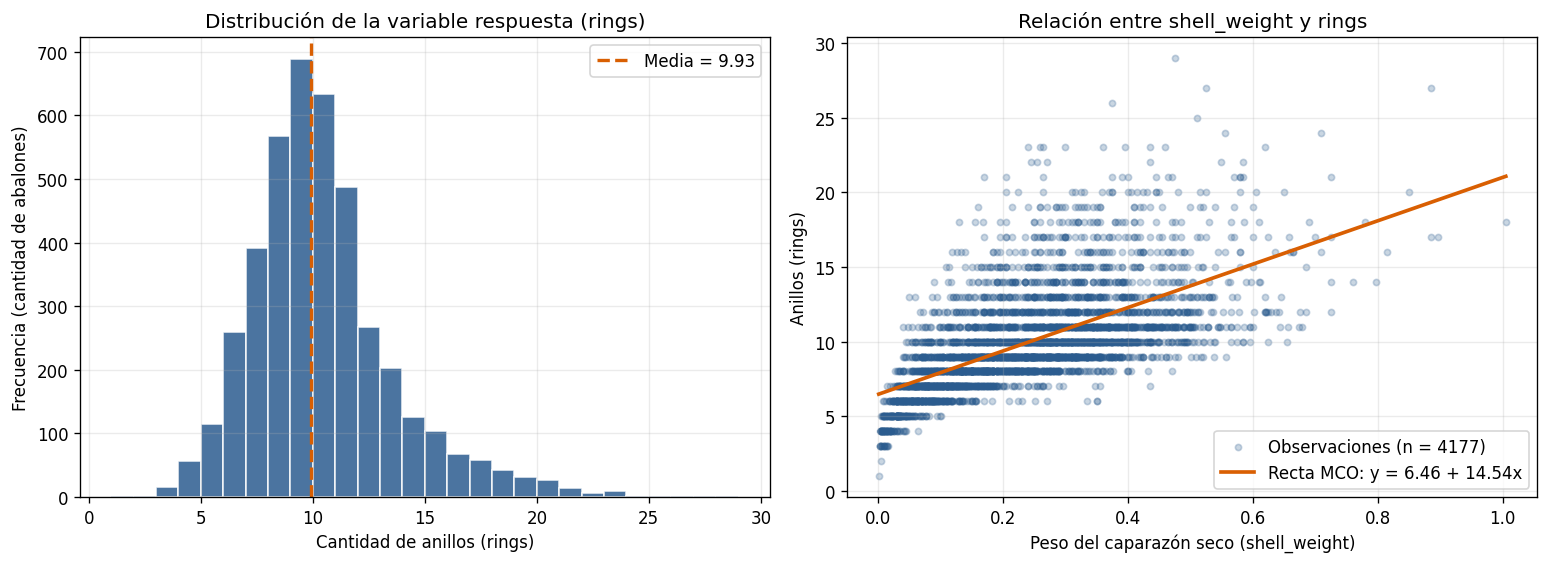

In [ ]:
# Estadísticas descriptivas de las variables numéricas
resumen = df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(4)
display(resumen)

# Visualización inicial sobre los datos reales
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Gráfico 1: Distribución de rings
axes[0].hist(df['rings'], bins=28, color='#2b5c8f', edgecolor='white', alpha=0.85)
axes[0].axvline(df['rings'].mean(), color='#d95f02', linestyle='--', linewidth=2, label=f"Media = {df['rings'].mean():.2f}")
axes[0].set_title('Distribución de la variable respuesta (rings)')
axes[0].set_xlabel('Cantidad de anillos (rings)')
axes[0].set_ylabel('Frecuencia (cantidad de abalones)')
axes[0].legend()
axes[0].grid(alpha=0.25)

# Gráfico 2: Dispersión shell_weight vs rings con recta de mínimos cuadrados
x = df['shell_weight'].values
y = df['rings'].values
b1, b0 = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 200)

axes[1].scatter(x, y, alpha=0.25, s=14, color='#2b5c8f', label='Observaciones (n = 4177)')
axes[1].plot(x_line, b0 + b1 * x_line, color='#d95f02', linewidth=2.2, label=f'Recta MCO: y = {b0:.2f} + {b1:.2f}x')
axes[1].set_title('Relación entre shell_weight y rings')
axes[1].set_xlabel('Peso del caparazón seco (shell_weight)')
axes[1].set_ylabel('Anillos (rings)')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

---
# Parte A — Complementos de Análisis Matemático
## A.1 Derivación (`rings` en función de `whole_weight`)
*Responsable: Pato*

### Desarrollo analítico y resultados del ejercicio A.1

1. **Ajuste del modelo cuadrático y lineal:**
   Sea $x = \text{whole\_weight}$ (peso entero del abalón, en unidades de $200\text{ g}$) e $y = \text{rings}$ (cantidad de anillos del caparazón). Al ajustar por mínimos cuadrados sobre las $n = 4177$ observaciones se obtiene:
   - **Modelo cuadrático:**
     $$\hat{y}(x) = \hat{\beta}_0 + \hat{\beta}_1 x + \hat{\beta}_2 x^2 = 5{,}6206 + 7{,}5174\,x - 2{,}0673\,x^2 \qquad (R^2 = 0{,}3323)$$
   - **Modelo lineal (para comparación):**
     $$\hat{y}_{\text{lin}}(x) = 6{,}9892 + 3{,}5529\,x \qquad (R^2 = 0{,}2920)$$

2. **Derivada primera y evaluación en dos puntos del rango observado ($[0{,}0020;\; 2{,}8255]$):**
   Derivando el polinomio de segundo grado respecto de $x$:
   $$\frac{d\hat{y}}{dx} = \hat{\beta}_1 + 2\hat{\beta}_2 x = 7{,}5174 + 2(-2{,}0673)x = 7{,}5174 - 4{,}1345\,x$$
   Evaluamos en dos valores representativos dentro del rango observado:
   - **Ejemplar joven/liviano ($x_1 = 0{,}30$, equivalente a $60\text{ g}$):**
     $$\left.\frac{d\hat{y}}{dx}\right|_{x=0{,}30} = 7{,}517390 - 4{,}134543(0{,}30) = 6{,}2770 \text{ anillos / unidad de peso}$$
     *Interpretación:* Cuando un abalón tiene un peso entero de $0{,}30$ unidades ($60\text{ g}$), la tasa instantánea de cambio estimada es de $6{,}28$ anillos por cada unidad adicional de `whole_weight` (o equivalentemente, $\approx 0{,}63$ anillos más por cada $0{,}10$ unidades / $20\text{ g}$ de incremento de peso).
   - **Ejemplar adulto/pesado ($x_2 = 1{,}50$, equivalente a $300\text{ g}$):**
     $$\left.\frac{d\hat{y}}{dx}\right|_{x=1{,}50} = 7{,}517390 - 4{,}134543(1{,}50) = 1{,}3156 \text{ anillos / unidad de peso}$$
     *Interpretación:* Cuando el abalón alcanza $1{,}50$ unidades de peso ($300\text{ g}$), la tasa de cambio cae a $1{,}32$ anillos por unidad de peso ($\approx 0{,}13$ anillos por cada $0{,}10$ unidades de peso adicional), casi cinco veces menor que en la etapa juvenil.

3. **Comparación con la derivada del modelo lineal:**
   - En el **modelo lineal**, la derivada es constante en todo el dominio:
     $$\frac{d\hat{y}_{\text{lin}}}{dx} = 3{,}5529 \text{ anillos / unidad de peso}$$
     Esto supone que el vínculo entre masa corporal y edad (anillos) es rígidamente proporcional durante toda la vida del molusco: ganar $0{,}10$ unidades de peso implicaría siempre sumar $\approx 0{,}36$ anillos, sin importar si el ejemplar es una larva recién asentada o un adulto viejo.
   - En cambio, el **modelo cuadrático** tiene una derivada que decrece linealmente con $x$ ($\hat{\beta}_2 < 0$), lo que permite reflejar que en etapas tempranas pequeños incrementos absolutos de peso se asocian a varios anillos nuevos, mientras que en adultos grandes el animal puede variar mucho de peso (por reservas, gónadas o contenido de agua) con cambios mucho menores o más dispersos en el número de anillos.

4. **Punto crítico, clasificación con la derivada segunda y análisis en el dominio:**
   - Igualando la derivada primera a cero:
     $$\frac{d\hat{y}}{dx} = 0 \iff 7{,}517390 - 4{,}134543\,x_c = 0 \implies x_c = -\frac{\hat{\beta}_1}{2\hat{\beta}_2} = \frac{7{,}517390}{4{,}134543} = 1{,}8182 \text{ unidades de peso } (\approx 363{,}6\text{ g})$$
     En dicho punto el modelo estima $\hat{y}(x_c) = 12{,}4546$ anillos.
   - **Clasificación con la derivada segunda:**
     $$\frac{d^2\hat{y}}{dx^2} = 2\hat{\beta}_2 = -4{,}1345 < 0$$
     Al ser estrictamente negativa en todo $\mathbb{R}$, la función es cóncava hacia abajo y $x_c = 1{,}8182$ es un **máximo absoluto**.
   - **Ubicación respecto del rango observado:** El rango efectivo de `whole_weight` en el dataset es $[0{,}0020;\; 2{,}8255]$, por lo que **el punto crítico cae dentro del rango observado** ($130$ abalones, el $3{,}11\%$ de la muestra, tienen `whole_weight` $> 1{,}8182$).
   - **Interpretación en el lenguaje del dominio:** Biológicamente, un abalón no "rejuvenece" ni pierde anillos por engordar más allá de $1{,}82$ unidades de peso. Que la parábola empiece a decrecer para $x > 1{,}8182$ evidencia una **limitación estructural del polinomio cuadrático**: por simetría algebraica, para curvarse y capturar la desaceleración inicial está obligado a doblar hacia abajo luego de su vértice, cuando el fenómeno real tiende a una meseta (asíntota) con alta dispersión en ejemplares grandes.


Concepto,Resultado
Modelo cuadrático y_hat(x),5.620558 + 7.517390·x - 2.067271·x² (R² = 0.3323)
Modelo lineal y_lin(x),6.989239 + 3.552909·x (R² = 0.2920)
Derivada primera cuadrática dŷ/dx,7.517390 - 4.134543·x
dŷ/dx evaluada en x₁ = 0.30 (joven/liviano),6.2770 anillos/unidad de peso (ŷ = 7.69 anillos)
dŷ/dx evaluada en x₂ = 1.50 (adulto/pesado),1.3156 anillos/unidad de peso (ŷ = 12.25 anillos)
Derivada modelo lineal dŷ_lin/dx,3.5529 anillos/unidad de peso (constante)
Punto crítico (dŷ/dx = 0),"x_c = 1.8182 unidades de peso, ŷ(x_c) = 12.4546 anillos"
Derivada segunda d²ŷ/dx²,-4.1345 (< 0 → Máximo absoluto)
"¿x_c cae en el rango [0.0020, 2.8255]?","Sí (130 abalones, 3.11% superan x_c)"


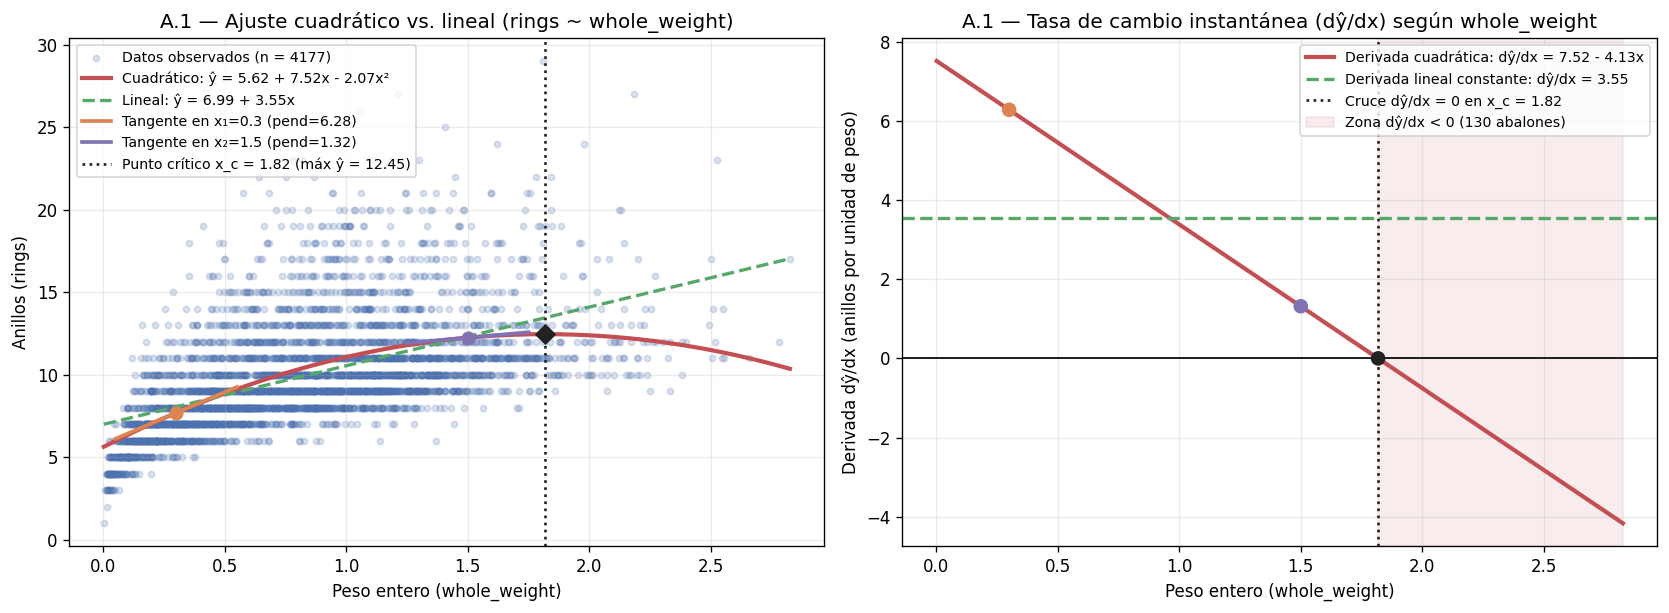

In [ ]:
# === EJERCICIO A.1: Derivación (rings en función de whole_weight) ===
x_ww = df['whole_weight'].values
y_rings = df['rings'].values

# 1. Ajuste del modelo cuadrático: y_hat(x) = beta0 + beta1*x + beta2*x^2
# np.polyfit(x, y, 2) devuelve coeficientes de mayor a menor grado: [beta2, beta1, beta0]
beta2_q, beta1_q, beta0_q = np.polyfit(x_ww, y_rings, 2)

# Ajuste del modelo lineal para comparación: y_lin(x) = beta0_l + beta1_l*x
beta1_l, beta0_l = np.polyfit(x_ww, y_rings, 1)

# Cálculo de R^2 para ambos modelos
y_hat_q = beta0_q + beta1_q * x_ww + beta2_q * (x_ww ** 2)
y_hat_l = beta0_l + beta1_l * x_ww
stc_ww = np.sum((y_rings - y_rings.mean()) ** 2)
r2_q = 1 - np.sum((y_rings - y_hat_q) ** 2) / stc_ww
r2_l = 1 - np.sum((y_rings - y_hat_l) ** 2) / stc_ww

# 2. Función derivada del modelo cuadrático: dy_hat/dx = beta1_q + 2*beta2_q*x
def dy_dx_cuad(x_val):
    return beta1_q + 2 * beta2_q * x_val

def y_cuad(x_val):
    return beta0_q + beta1_q * x_val + beta2_q * (x_val ** 2)

# Evaluación en dos valores dentro del rango observado [0.0020, 2.8255]
x1_eval, x2_eval = 0.30, 1.50
dy_x1, dy_x2 = dy_dx_cuad(x1_eval), dy_dx_cuad(x2_eval)

# 3. Punto crítico (dy/dx = 0) y derivada segunda
x_crit = -beta1_q / (2 * beta2_q)
y_crit = y_cuad(x_crit)
d2y_dx2 = 2 * beta2_q
x_min_obs, x_max_obs = x_ww.min(), x_ww.max()
en_rango = (x_min_obs <= x_crit <= x_max_obs)
n_mayores_xc = int(np.sum(x_ww > x_crit))

# Resumen estructurado de resultados A.1
tabla_a1 = pd.DataFrame([
    {"Concepto": "Modelo cuadrático y_hat(x)", "Resultado": f"{beta0_q:.6f} + {beta1_q:.6f}·x - {abs(beta2_q):.6f}·x² (R² = {r2_q:.4f})"},
    {"Concepto": "Modelo lineal y_lin(x)", "Resultado": f"{beta0_l:.6f} + {beta1_l:.6f}·x (R² = {r2_l:.4f})"},
    {"Concepto": "Derivada primera cuadrática dŷ/dx", "Resultado": f"{beta1_q:.6f} - {abs(2*beta2_q):.6f}·x"},
    {"Concepto": f"dŷ/dx evaluada en x₁ = {x1_eval:.2f} (joven/liviano)", "Resultado": f"{dy_x1:.4f} anillos/unidad de peso (ŷ = {y_cuad(x1_eval):.2f} anillos)"},
    {"Concepto": f"dŷ/dx evaluada en x₂ = {x2_eval:.2f} (adulto/pesado)", "Resultado": f"{dy_x2:.4f} anillos/unidad de peso (ŷ = {y_cuad(x2_eval):.2f} anillos)"},
    {"Concepto": "Derivada modelo lineal dŷ_lin/dx", "Resultado": f"{beta1_l:.4f} anillos/unidad de peso (constante)"},
    {"Concepto": "Punto crítico (dŷ/dx = 0)", "Resultado": f"x_c = {x_crit:.4f} unidades de peso, ŷ(x_c) = {y_crit:.4f} anillos"},
    {"Concepto": "Derivada segunda d²ŷ/dx²", "Resultado": f"{d2y_dx2:.4f} (< 0 → Máximo absoluto)"},
    {"Concepto": f"¿x_c cae en el rango [{x_min_obs:.4f}, {x_max_obs:.4f}]?", "Resultado": f"Sí ({n_mayores_xc} abalones, {100*n_mayores_xc/len(x_ww):.2f}% superan x_c)"}
])
display(tabla_a1)

# 4. Visualización comparativa: Curvas ajustadas, rectas tangentes y función derivada
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
x_grid = np.linspace(x_min_obs, x_max_obs, 300)

# Panel izquierdo: Datos + Modelo Cuadrático + Modelo Lineal + Tangentes + Punto Crítico
axes[0].scatter(x_ww, y_rings, alpha=0.20, s=14, color='#4c72b0', label='Datos observados (n = 4177)')
axes[0].plot(x_grid, y_cuad(x_grid), color='#c44e52', linewidth=2.5, label=f'Cuadrático: ŷ = {beta0_q:.2f} + {beta1_q:.2f}x - {abs(beta2_q):.2f}x²')
axes[0].plot(x_grid, beta0_l + beta1_l * x_grid, color='#55a868', linestyle='--', linewidth=2, label=f'Lineal: ŷ = {beta0_l:.2f} + {beta1_l:.2f}x')

# Trazado de segmentos tangentes en x1 y x2
for x_pt, dy_pt, col_pt, lbl in [(x1_eval, dy_x1, '#dd8452', f'Tangente en x₁={x1_eval} (pend={dy_x1:.2f})'),
                                 (x2_eval, dy_x2, '#8172b3', f'Tangente en x₂={x2_eval} (pend={dy_x2:.2f})')]:
    dx_seg = np.linspace(x_pt - 0.25, x_pt + 0.25, 50)
    y_seg = y_cuad(x_pt) + dy_pt * (dx_seg - x_pt)
    axes[0].plot(dx_seg, y_seg, color=col_pt, linewidth=2.2, label=lbl)
    axes[0].scatter([x_pt], [y_cuad(x_pt)], color=col_pt, s=55, zorder=5)

axes[0].axvline(x_crit, color='#222222', linestyle=':', linewidth=1.6, label=f'Punto crítico x_c = {x_crit:.2f} (máx ŷ = {y_crit:.2f})')
axes[0].scatter([x_crit], [y_crit], color='#222222', s=65, marker='D', zorder=6)
axes[0].set_title('A.1 — Ajuste cuadrático vs. lineal (rings ~ whole_weight)')
axes[0].set_xlabel('Peso entero (whole_weight)')
axes[0].set_ylabel('Anillos (rings)')
axes[0].legend(fontsize=8.5, loc='upper left')
axes[0].grid(alpha=0.25)

# Panel derecho: Comparación de las derivadas dŷ/dx en el rango observado
axes[1].plot(x_grid, dy_dx_cuad(x_grid), color='#c44e52', linewidth=2.5, label='Derivada cuadrática: dŷ/dx = 7.52 - 4.13x')
axes[1].axhline(beta1_l, color='#55a868', linestyle='--', linewidth=2, label=f'Derivada lineal constante: dŷ/dx = {beta1_l:.2f}')
axes[1].axhline(0, color='#222222', linewidth=1.2)
axes[1].axvline(x_crit, color='#222222', linestyle=':', linewidth=1.6, label=f'Cruce dŷ/dx = 0 en x_c = {x_crit:.2f}')
axes[1].scatter([x1_eval, x2_eval, x_crit], [dy_x1, dy_x2, 0], color=['#dd8452', '#8172b3', '#222222'], s=60, zorder=5)
axes[1].axvspan(x_crit, x_max_obs, color='#c44e52', alpha=0.10, label='Zona dŷ/dx < 0 (130 abalones)')
axes[1].set_title('A.1 — Tasa de cambio instantánea (dŷ/dx) según whole_weight')
axes[1].set_xlabel('Peso entero (whole_weight)')
axes[1].set_ylabel('Derivada dŷ/dx (anillos por unidad de peso)')
axes[1].legend(fontsize=8.5, loc='upper right')
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## A.2 Derivadas parciales y ecuaciones normales (`rings` sobre `shell_weight`)
*Responsable: Pato*

### Desarrollo analítico paso a paso ("a mano") y contraste numérico

1. **Función objetivo de mínimos cuadrados:**
   Para la regresión lineal simple de $y = \text{rings}$ sobre $x = \text{shell\_weight}$, la suma de los cuadrados de las desviaciones verticales en función de los parámetros $(b_0, b_1)$ es:
   $$f(b_0, b_1) = \sum_{i=1}^{n} \left[ y_i - (b_0 + b_1 \cdot x_i) \right]^2 = \sum_{i=1}^{n} \left( y_i - b_0 - b_1 x_i \right)^2$$

2. **Cálculo a mano de las derivadas parciales $\frac{\partial f}{\partial b_0}$ y $\frac{\partial f}{\partial b_1}$:**
   Aplicando la linealidad de la sumatoria y la regla de la cadena a cada término $u_i^2 = (y_i - b_0 - b_1 x_i)^2$:
   - **Derivada parcial respecto de $b_0$** (tratando a $b_1$ como constante, donde $\frac{\partial}{\partial b_0}(y_i - b_0 - b_1 x_i) = -1$):
     $$\frac{\partial f}{\partial b_0} = \sum_{i=1}^{n} 2 \left[ y_i - (b_0 + b_1 x_i) \right] \cdot (-1) = -2 \sum_{i=1}^{n} \left( y_i - b_0 - b_1 x_i \right)$$
   - **Derivada parcial respecto de $b_1$** (tratando a $b_0$ como constante, donde $\frac{\partial}{\partial b_1}(y_i - b_0 - b_1 x_i) = -x_i$):
     $$\frac{\partial f}{\partial b_1} = \sum_{i=1}^{n} 2 \left[ y_i - (b_0 + b_1 x_i) \right] \cdot (-x_i) = -2 \sum_{i=1}^{n} x_i \left( y_i - b_0 - b_1 x_i \right)$$

3. **Sistema de ecuaciones normales y resolución analítica hasta $\hat{\beta}_1$ y $\hat{\beta}_0$:**
   Buscamos el punto estacionario igualando ambas derivadas parciales a cero en $(b_0, b_1) = (\hat{\beta}_0, \hat{\beta}_1)$:
   $$\begin{cases} \dfrac{\partial f}{\partial b_0} = 0 \iff -2 \displaystyle\sum_{i=1}^{n} (y_i - \hat{\beta}_0 - \hat{\beta}_1 x_i) = 0 \\[10pt] \dfrac{\partial f}{\partial b_1} = 0 \iff -2 \displaystyle\sum_{i=1}^{n} x_i (y_i - \hat{\beta}_0 - \hat{\beta}_1 x_i) = 0 \end{cases}$$
   Dividiendo ambas ecuaciones por $-2$ y distribuyendo el símbolo de sumatoria (recordando que $\sum_{i=1}^n \hat{\beta}_0 = n\hat{\beta}_0$), obtenemos el **sistema de ecuaciones normales**:
   $$\begin{cases} (1) \quad n\hat{\beta}_0 + \hat{\beta}_1 \displaystyle\sum_{i=1}^{n} x_i = \displaystyle\sum_{i=1}^{n} y_i \\[10pt] (2) \quad \hat{\beta}_0 \displaystyle\sum_{i=1}^{n} x_i + \hat{\beta}_1 \displaystyle\sum_{i=1}^{n} x_i^2 = \displaystyle\sum_{i=1}^{n} x_i y_i \end{cases}$$
   - **Paso A (Despeje de $\hat{\beta}_0$ en función de $\hat{\beta}_1$):** Dividiendo la ecuación $(1)$ por $n$ y usando las definiciones de las medias muestrales $\bar{x} = \frac{1}{n}\sum_{i=1}^n x_i$ e $\bar{y} = \frac{1}{n}\sum_{i=1}^n y_i$:
     $$\hat{\beta}_0 + \hat{\beta}_1 \bar{x} = \bar{y} \implies \boxed{\hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \cdot \bar{x}}$$
   - **Paso B (Sustitución en la segunda ecuación normal):** Reemplazando $\hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \bar{x}$ y $\sum_{i=1}^n x_i = n\bar{x}$ en la ecuación $(2)$:
     $$(\bar{y} - \hat{\beta}_1 \bar{x})(n\bar{x}) + \hat{\beta}_1 \sum_{i=1}^{n} x_i^2 = \sum_{i=1}^{n} x_i y_i$$
     $$n\bar{x}\bar{y} - \hat{\beta}_1 n\bar{x}^2 + \hat{\beta}_1 \sum_{i=1}^{n} x_i^2 = \sum_{i=1}^{n} x_i y_i$$
     Agrupando los términos con $\hat{\beta}_1$ a la izquierda y pasando $n\bar{x}\bar{y}$ a la derecha:
     $$\hat{\beta}_1 \left( \sum_{i=1}^{n} x_i^2 - n\bar{x}^2 \right) = \sum_{i=1}^{n} x_i y_i - n\bar{x}\bar{y}$$
   - **Paso C (Identificación con $S_{xx}$ y $S_{xy}$):** Desarrollando las sumas de desviaciones respecto de la media:
     $$S_{xx} = \sum_{i=1}^{n} (x_i - \bar{x})^2 = \sum_{i=1}^{n} (x_i^2 - 2\bar{x}x_i + \bar{x}^2) = \sum_{i=1}^{n} x_i^2 - 2\bar{x}(n\bar{x}) + n\bar{x}^2 = \sum_{i=1}^{n} x_i^2 - n\bar{x}^2$$
     $$S_{xy} = \sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y}) = \sum_{i=1}^{n} (x_i y_i - x_i\bar{y} - \bar{x}y_i + \bar{x}\bar{y}) = \sum_{i=1}^{n} x_i y_i - n\bar{x}\bar{y} - n\bar{x}\bar{y} + n\bar{x}\bar{y} = \sum_{i=1}^{n} x_i y_i - n\bar{x}\bar{y}$$
     Por lo tanto, dado que $S_{xx} > 0$, queda demostrado que:
     $$\hat{\beta}_1 \cdot S_{xx} = S_{xy} \implies \boxed{\hat{\beta}_1 = \frac{S_{xy}}{S_{xx}}}$$

4. **Resultado numérico y contraste con librería:**
   - $n = 4177$, $\bar{x} = 0{,}23883086$, $\bar{y} = 9{,}93368446$, $S_{xx} = 80{,}91995225$, $S_{xy} = 1176{,}22614807$.
   - Por fórmulas manuales: $\hat{\beta}_1 = \frac{1176{,}22614807}{80{,}91995225} = 14{,}535675260987$ y $\hat{\beta}_0 = 9{,}93368446 - 14{,}53567526 \cdot (0{,}23883086) = 6{,}462116646996$.
   - Por `scipy.stats.linregress` / `np.polyfit`: $\hat{\beta}_1 = 14{,}535675260987$ y $\hat{\beta}_0 = 6{,}462116646996$ (diferencia absoluta $= 0{,}00 \times 10^0$).
   - **Recta de mínimos cuadrados obtenida:**
     $$\boxed{\hat{y}(x) = 6{,}4621 + 14{,}5357 \cdot x}$$


Magnitud,Fórmula / Vía Manual,Librería Python (scipy),Diferencia Absoluta
Tamaño muestral (n),4177,4177,-
Media de shell_weight (x̄),0.23883086,0.23883086,0.00e+00
Media de rings (ȳ),9.93368446,9.93368446,0.00e+00
Suma de cuadrados Sxx,80.91995225,80.91995225,5.68e-14
Suma de productos Sxy,1176.22614807,1176.22614807,1.36e-12
Pendiente estimada (β̂₁ = Sxy / Sxx),14.535675260987,14.535675260987,0.00e+00
Ordenada al origen (β̂₀ = ȳ - β̂₁·x̄),6.462116646996,6.462116646996,0.00e+00
"Gradiente en el óptimo (∂f/∂b₀, ∂f/∂b₁)","(1.99e-12, 7.67e-13)","(0.00e+00, 0.00e+00)",Óptimo exacto
"Mínimo de f(b₀, b₁) = SCE",26313.389274,26313.389274,0.00e+00
Recta ajustada final,ŷ = 6.4621 + 14.5357·x,ŷ = 6.4621 + 14.5357·x,Coincidencia exacta


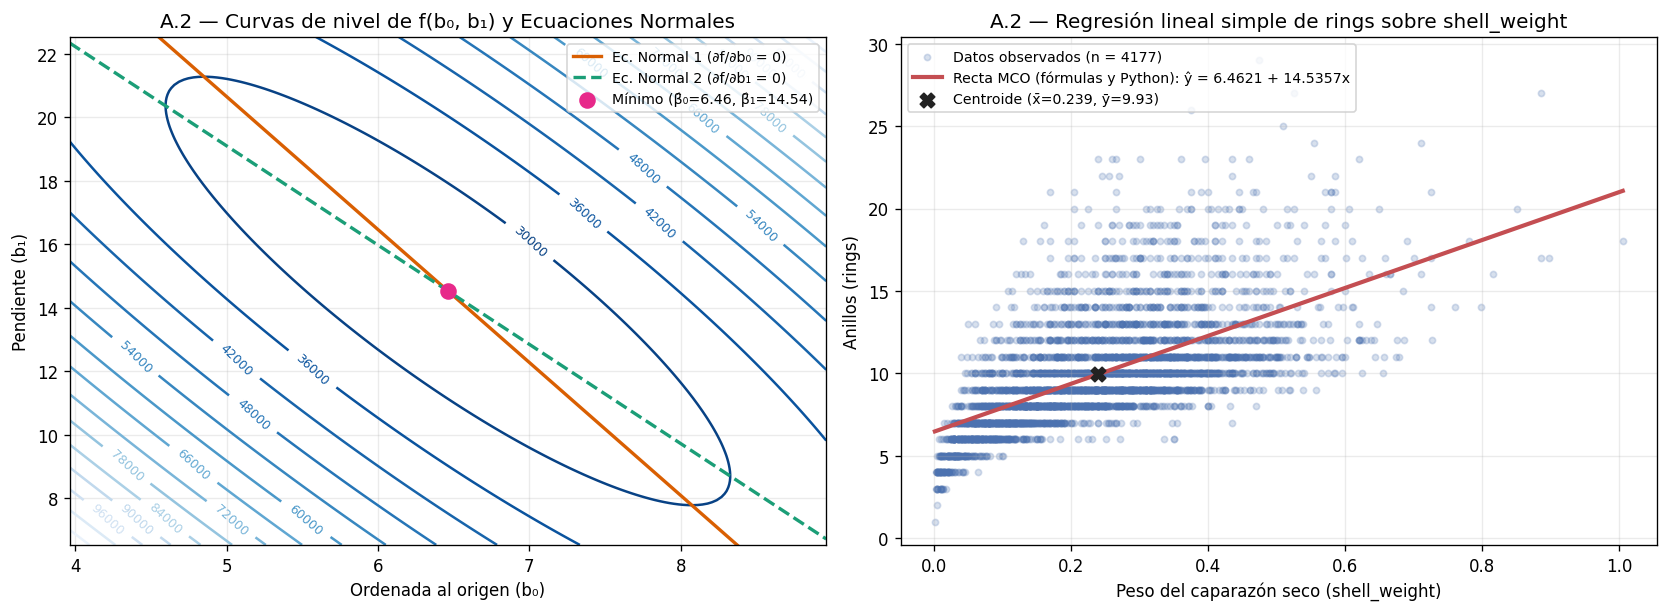

In [ ]:
# === EJERCICIO A.2: Derivadas parciales y ecuaciones normales (rings sobre shell_weight) ===
from scipy import stats

x_sw = df['shell_weight'].values
y_rings = df['rings'].values
n_obs = len(x_sw)

# 1. Cálculo "a mano" usando sumatorias elementales y las fórmulas deducidas
sum_x = np.sum(x_sw)
sum_y = np.sum(y_rings)
sum_x2 = np.sum(x_sw ** 2)
sum_xy = np.sum(x_sw * y_rings)

x_bar = sum_x / n_obs
y_bar = sum_y / n_obs

# Sumas centradas Sxx y Sxy (verificadas por definición y por identidad expandida)
Sxx = np.sum((x_sw - x_bar) ** 2)
Sxy = np.sum((x_sw - x_bar) * (y_rings - y_bar))

beta1_manual = Sxy / Sxx
beta0_manual = y_bar - beta1_manual * x_bar

# 2. Cálculo mediante herramientas de regresión lineal de Python (scipy y numpy)
reg_scipy = stats.linregress(x_sw, y_rings)
beta1_scipy, beta0_scipy = reg_scipy.slope, reg_scipy.intercept
beta1_np, beta0_np = np.polyfit(x_sw, y_rings, 1)

# Verificación de que las derivadas parciales en el óptimo se anulan (dentro de precisión de máquina)
df_db0_opt = -2 * np.sum(y_rings - beta0_manual - beta1_manual * x_sw)
df_db1_opt = -2 * np.sum(x_sw * (y_rings - beta0_manual - beta1_manual * x_sw))
f_min_sce = np.sum((y_rings - (beta0_manual + beta1_manual * x_sw)) ** 2)

# Tabla de contraste y valores de control (insumo base para Parte B de Mateo)
tabla_a2 = pd.DataFrame([
    {"Magnitud": "Tamaño muestral (n)", "Fórmula / Vía Manual": f"{n_obs}", "Librería Python (scipy)": f"{n_obs}", "Diferencia Absoluta": "-"},
    {"Magnitud": "Media de shell_weight (x̄)", "Fórmula / Vía Manual": f"{x_bar:.8f}", "Librería Python (scipy)": f"{x_sw.mean():.8f}", "Diferencia Absoluta": f"{abs(x_bar - x_sw.mean()):.2e}"},
    {"Magnitud": "Media de rings (ȳ)", "Fórmula / Vía Manual": f"{y_bar:.8f}", "Librería Python (scipy)": f"{y_rings.mean():.8f}", "Diferencia Absoluta": f"{abs(y_bar - y_rings.mean()):.2e}"},
    {"Magnitud": "Suma de cuadrados Sxx", "Fórmula / Vía Manual": f"{Sxx:.8f}", "Librería Python (scipy)": f"{sum_x2 - n_obs*(x_bar**2):.8f}", "Diferencia Absoluta": f"{abs(Sxx - (sum_x2 - n_obs*(x_bar**2))):.2e}"},
    {"Magnitud": "Suma de productos Sxy", "Fórmula / Vía Manual": f"{Sxy:.8f}", "Librería Python (scipy)": f"{sum_xy - n_obs*x_bar*y_bar:.8f}", "Diferencia Absoluta": f"{abs(Sxy - (sum_xy - n_obs*x_bar*y_bar)):.2e}"},
    {"Magnitud": "Pendiente estimada (β̂₁ = Sxy / Sxx)", "Fórmula / Vía Manual": f"{beta1_manual:.12f}", "Librería Python (scipy)": f"{beta1_scipy:.12f}", "Diferencia Absoluta": f"{abs(beta1_manual - beta1_scipy):.2e}"},
    {"Magnitud": "Ordenada al origen (β̂₀ = ȳ - β̂₁·x̄)", "Fórmula / Vía Manual": f"{beta0_manual:.12f}", "Librería Python (scipy)": f"{beta0_scipy:.12f}", "Diferencia Absoluta": f"{abs(beta0_manual - beta0_scipy):.2e}"},
    {"Magnitud": "Gradiente en el óptimo (∂f/∂b₀, ∂f/∂b₁)", "Fórmula / Vía Manual": f"({df_db0_opt:.2e}, {df_db1_opt:.2e})", "Librería Python (scipy)": "(0.00e+00, 0.00e+00)", "Diferencia Absoluta": "Óptimo exacto"},
    {"Magnitud": "Mínimo de f(b₀, b₁) = SCE", "Fórmula / Vía Manual": f"{f_min_sce:.6f}", "Librería Python (scipy)": f"{f_min_sce:.6f}", "Diferencia Absoluta": "0.00e+00"},
    {"Magnitud": "Recta ajustada final", "Fórmula / Vía Manual": f"ŷ = {beta0_manual:.4f} + {beta1_manual:.4f}·x", "Librería Python (scipy)": f"ŷ = {beta0_scipy:.4f} + {beta1_scipy:.4f}·x", "Diferencia Absoluta": "Coincidencia exacta"}
])
display(tabla_a2)

# 3. Visualización: Curvas de nivel de f(b0, b1) + intersección de Ecuaciones Normales y Recta Ajustada
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Panel izquierdo: Superficie de costo f(b0, b1) y rectas de las dos ecuaciones normales
b0_grid = np.linspace(beta0_manual - 2.5, beta0_manual + 2.5, 160)
b1_grid = np.linspace(beta1_manual - 8.0, beta1_manual + 8.0, 160)
B0, B1 = np.meshgrid(b0_grid, b1_grid)

# Usando descomposición algebraica rápida de f(b0, b1)
# f(b0, b1) = SCE_min + n*(b0 - beta0 + (b1 - beta1)*x_bar)^2 + Sxx*(b1 - beta1)^2
F_grid = f_min_sce + n_obs * ((B0 - beta0_manual) + (B1 - beta1_manual) * x_bar) ** 2 + Sxx * (B1 - beta1_manual) ** 2

cs = axes[0].contour(B0, B1, F_grid, levels=14, cmap='Blues_r')
axes[0].clabel(cs, inline=True, fontsize=7.5, fmt='%.0f')

# Ecuación normal 1 (∂f/∂b0 = 0): b1 = (y_bar - b0) / x_bar
b1_eq1 = (y_bar - b0_grid) / x_bar
# Ecuación normal 2 (∂f/∂b1 = 0): b1 = (sum_xy - b0 * sum_x) / sum_x2
b1_eq2 = (sum_xy - b0_grid * sum_x) / sum_x2

axes[0].plot(b0_grid, b1_eq1, color='#d95f02', linewidth=2, label='Ec. Normal 1 (∂f/∂b₀ = 0)')
axes[0].plot(b0_grid, b1_eq2, color='#1b9e77', linestyle='--', linewidth=2, label='Ec. Normal 2 (∂f/∂b₁ = 0)')
axes[0].scatter([beta0_manual], [beta1_manual], color='#e7298a', s=80, zorder=6,
                label=f'Mínimo (β̂₀={beta0_manual:.2f}, β̂₁={beta1_manual:.2f})')
axes[0].set_xlim(b0_grid.min(), b0_grid.max())
axes[0].set_ylim(b1_grid.min(), b1_grid.max())
axes[0].set_title('A.2 — Curvas de nivel de f(b₀, b₁) y Ecuaciones Normales')
axes[0].set_xlabel('Ordenada al origen (b₀)')
axes[0].set_ylabel('Pendiente (b₁)')
axes[0].legend(fontsize=8.5, loc='upper right')
axes[0].grid(alpha=0.25)

# Panel derecho: Dispersión shell_weight vs rings y recta de mínimos cuadrados
x_line = np.linspace(x_sw.min(), x_sw.max(), 200)
axes[1].scatter(x_sw, y_rings, alpha=0.22, s=14, color='#4c72b0', label='Datos observados (n = 4177)')
axes[1].plot(x_line, beta0_manual + beta1_manual * x_line, color='#c44e52', linewidth=2.5,
             label=f'Recta MCO (fórmulas y Python): ŷ = {beta0_manual:.4f} + {beta1_manual:.4f}x')
axes[1].scatter([x_bar], [y_bar], color='#222222', s=75, marker='X', zorder=6,
                label=f'Centroide (x̄={x_bar:.3f}, ȳ={y_bar:.2f})')
axes[1].set_title('A.2 — Regresión lineal simple de rings sobre shell_weight')
axes[1].set_xlabel('Peso del caparazón seco (shell_weight)')
axes[1].set_ylabel('Anillos (rings)')
axes[1].legend(fontsize=8.5, loc='upper left')
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## A.3 Descenso del gradiente
*Responsable: Joaco*

In [ ]:
# Código A.3


---
# Parte B — Complementos de Estadística
## B.1 Varianza
*Responsable: Mateo*

In [ ]:
# Código B.1


## B.2 Regresión lineal simple
*Responsable: Mateo*

In [ ]:
# Código B.2


## B.3 Test de hipótesis
*Responsable: Mateo*

In [ ]:
# Código B.3


## B.4 Intervalos para la respuesta media y de predicción
*Responsable: Mateo*

In [ ]:
# Código B.4


## B.5 Regresión múltiple
*Responsable: Joaco*

In [ ]:
# Código B.5


---
# Parte C y Anexo I — Bitácora de uso de inteligencia artificial
*Consolidación: Pato (cada integrante agrega sus filas correspondientes)*

La cátedra evalúa el criterio con el que se utilizan asistentes de inteligencia artificial. En la siguiente tabla se documentan todas las interacciones cuyo resultado fue analizado, aceptado, modificado o rechazado durante el desarrollo del trabajo práctico:

| # | Fecha | Herramienta | Qué se le pidió | Resumen de la respuesta | ¿Se aceptó? | Cambios realizados y motivo | Ítem afectado |
| :---: | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **1** | 2026-11-02 | Claude Code | Plan del TP y explicación de B.5 | Plan por ítems, reparto de tareas entre los integrantes y explicación del modelo múltiple con código matricial. | Sí (Aceptado) | Se adoptó la división de tareas (Pato: A.1, A.2, Sección 1 y armado; Mateo: B.1–B.4; Joaco: B.5 y A.3) para no superponerse en el Colab. | B.5, organización general |
| **2** | 2026-11-02 | Antigravity (Gemini) | Configurar la carga del dataset `abalone.csv` en Google Colab y armar la vista exploratoria inicial (Sección 1: tabla de estadísticos descriptivos, histograma de `rings` y dispersión inicial). | Propuso inicialmente cargar el CSV montando Google Drive (`drive.mount('/content/drive')`), normalizar los nombres de columnas con espacios a `snake_case` y generar las tablas y gráficos descriptivos. | Aceptado con cambios (se rechazó usar Drive como fuente principal) | Se **rechazó** depender de `drive.mount` en la Celda 1 porque impediría que el resto del grupo (Mateo, Joaco) y los docentes ejecutaran el Colab desde sus cuentas. Se **modificó** para leer directamente desde la URL oficial del enunciado (`raw.githubusercontent.com/.../abalone.csv`) conservando el reemplazo de espacios por guiones bajos. | Sección 1 (Datos y objetivo) y Paso 0 del Colab |
| **3** | 2026-11-02 | Antigravity (Gemini) | Resolver el Ejercicio A.1: ajustar el modelo cuadrático y lineal de `rings` sobre `whole_weight`, calcular $d\hat{y}/dx$ en dos valores del rango observado, hallar y clasificar el punto crítico con la derivada segunda y graficar. | Entregó el ajuste cuadrático $\hat{y}(x) = 5{,}6206 + 7{,}5174x - 2{,}0673x^2$ ($R^2=0{,}3323$), la derivada $d\hat{y}/dx = 7{,}5174 - 4{,}1345x$ evaluada en $x_1=0{,}30$ ($6{,}28$) y $x_2=1{,}50$ ($1{,}32$), la comparación con la derivada lineal constante ($3{,}55$) y el punto crítico $x_c = 1{,}8182$ ($d^2\hat{y}/dx^2 = -4{,}1345 < 0$, máximo absoluto). | Aceptado con agregados de dominio | Se verificaron manualmente las derivadas primera y segunda y se agregó el conteo empírico de cuántos abalones de la muestra superan el punto crítico ($130$ ejemplares, $3{,}11\%$) para justificar biológicamente por qué la caída de la parábola para $x > 1{,}8182$ es una limitación del polinomio de grado 2. | Parte A — Ítem A.1 |
| **4** | 2026-11-02 | Antigravity (Gemini) | Resolver el Ejercicio A.2: desarrollar paso a paso $\partial f/\partial b_0$ y $\partial f/\partial b_1$, plantear y resolver el sistema de ecuaciones normales hasta $\hat{\beta}_1 = S_{xy}/S_{xx}$ y $\hat{\beta}_0 = \bar{y} - \hat{\beta}_1\bar{x}$, y contrastar los números en Python sobre `shell_weight` vs `rings`. | Desarrolló la deducción algebraica completa y verificó en Python que las fórmulas manuales ($S_{xx}=80{,}9200$, $S_{xy}=1176{,}2261$) y `scipy.stats.linregress` dan exactamente $\hat{\beta}_1 = 14{,}535675260987$ y $\hat{\beta}_0 = 6{,}462116646996$ ($\hat{y} = 6{,}4621 + 14{,}5357x$, diferencia $0{,}00$), graficando las curvas de nivel de $f(b_0,b_1)$ y las ecuaciones normales. | Aceptado con agregados algebraicos | Se exigió incluir explícitamente la demostración intermedia de las identidades $S_{xx} = \sum x_i^2 - n\bar{x}^2$ y $S_{xy} = \sum x_i y_i - n\bar{x}\bar{y}$ para no omitir pasos en el desarrollo a mano del Anexo II, y se exportaron los valores de control ($STC, SCR, SCE, \hat{\sigma}^2$) para la Parte B de Mateo. | Parte A — Ítem A.2 y Anexo II |
